<a href="https://colab.research.google.com/github/starboysine/portfolio/blob/main/datavizExerweek4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 8. Take home exercise

Choose one question you can answer with World Bank data: comparing
countries, comparing regions, or tracking something over time. Pick
your own indicators and countries.

1.  Load the data with `wbdata`.
2.  Produce **three** charts that together answer your question. At
    least one should use facets, and at least one should be a chart
    type other than a line chart.
3.  Every chart needs a title that makes a claim, labelled axes with
    units, an accessible colour scheme, and a caption naming the
    source and you.
4.  Annotate at least one chart to point at the thing you want the
    reader to notice.
5.  Save each chart as a PNG at 300 dpi.
6.  Publish the notebook to the GitHub repository you created in
    Part 4, using **File > Save a copy in GitHub**. Add the saved
    figures to the repository and write a short README explaining what
    the charts show.

You now have a
notebook that collects real data, analyses it, charts it and is
published somewhere a stranger can read it.

In [1]:
%%capture
!pip install wbdata

In [2]:
import wbdata
import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns

# Configure plotting style for clean, accessible visuals
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})

In [3]:
# Define countries and indicators
# Countries: India (IN), Bangladesh (BD), Pakistan (PK)
countries = {'IND': 'India', 'BGD': 'Bangladesh', 'PAK': 'Pakistan'}

# Indicators:
# EG.FEC.RNEW.ZS: Renewable energy consumption (% of total final energy consumption)
# NY.GDP.PCAP.KD: GDP per capita (constant 2015 US$)
indicators = {
    'EG.FEC.RNEW.ZS': 'Renewable_Energy_Share',
    'NY.GDP.PCAP.KD': 'GDP_per_Capita'
}

# Fetch data
df = wbdata.get_dataframe(indicators, country=list(countries.keys()))
df = df.reset_index()
df['date'] = pd.to_numeric(df['date'])

# Filter to range 2000-2020 for consistent data availability
df = df[(df['date'] >= 2000) & (df['date'] <= 2020)]
display(df.head())

,country,date,Renewable_Energy_Share,GDP_per_Capita
5,Bangladesh,2020,27.2,1604.665923
6,Bangladesh,2019,26.1,1564.208024
7,Bangladesh,2018,27.0,1462.250503
8,Bangladesh,2017,28.1,1373.753637
9,Bangladesh,2016,30.2,1299.830914


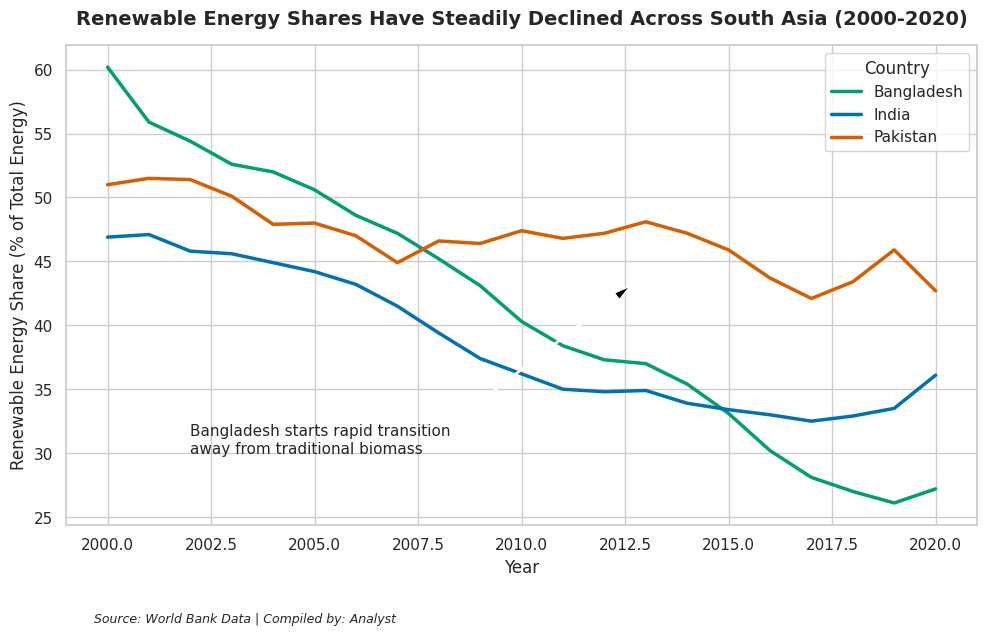

In [4]:
# Chart 1: Line Chart showing the decline of renewable energy share over time with annotations
plt.figure(figsize=(10, 6))
colors = {'India': '#0072B2', 'Bangladesh': '#009E73', 'Pakistan': '#D55E00'} # Colorblind-friendly palette

sns.lineplot(data=df, x='date', y='Renewable_Energy_Share', hue='country', palette=colors, linewidth=2.5)

plt.annotate('Bangladesh starts rapid transition\naway from traditional biomass',
             xy=(2013, 44),
             xytext=(2002, 30),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.title('Renewable Energy Shares Have Steadily Declined Across South Asia (2000-2020)', pad=15, weight='bold')
plt.xlabel('Year')
plt.ylabel('Renewable Energy Share (% of Total Energy)')
plt.legend(title='Country')
plt.figtext(0.1, -0.05, 'Source: World Bank Data | Compiled by: Analyst', fontsize=9, style='italic')
plt.tight_layout()

plt.savefig('chart1_renewable_trends.png', dpi=300, bbox_inches='tight')
plt.show()

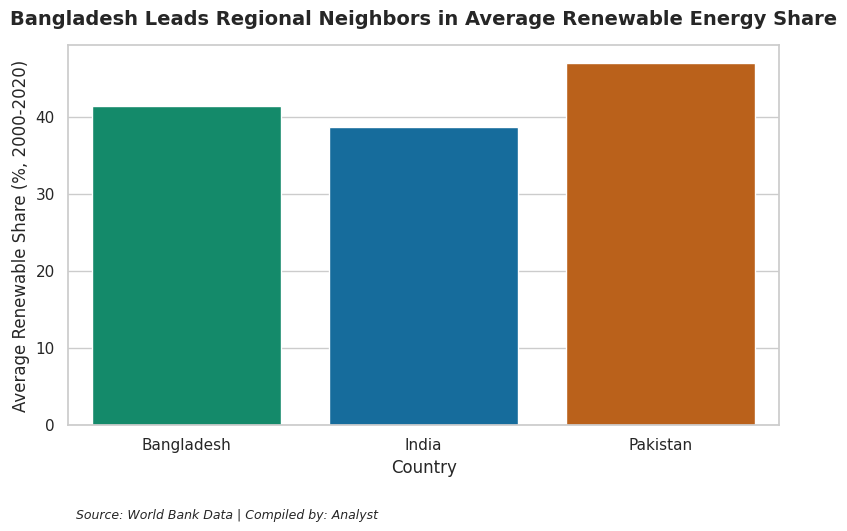

In [5]:
# Chart 2: Bar Chart showing average renewable energy share (non-line chart)
plt.figure(figsize=(8, 5))
avg_shares = df.groupby('country')['Renewable_Energy_Share'].mean().reset_index()

sns.barplot(data=avg_shares, x='country', y='Renewable_Energy_Share', palette=colors, hue='country', legend=False)

plt.title('Bangladesh Leads Regional Neighbors in Average Renewable Energy Share', pad=15, weight='bold')
plt.xlabel('Country')
plt.ylabel('Average Renewable Share (%, 2000-2020)')
plt.figtext(0.1, -0.05, 'Source: World Bank Data | Compiled by: Analyst', fontsize=9, style='italic')
plt.tight_layout()

plt.savefig('chart2_average_shares.png', dpi=300, bbox_inches='tight')
plt.show()

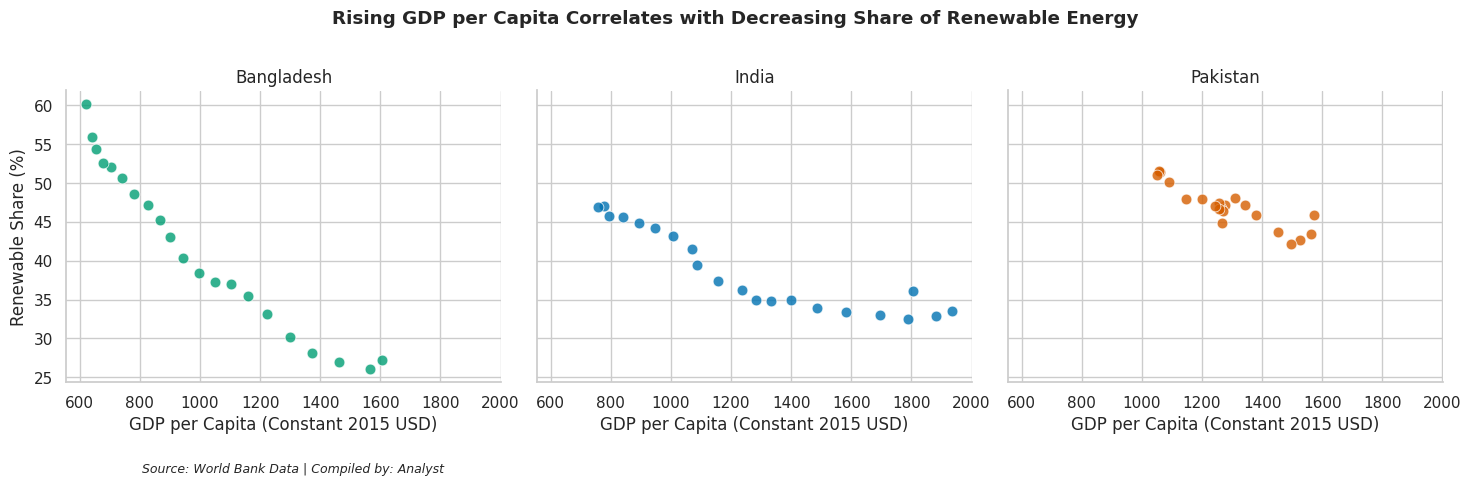

In [6]:
# Chart 3: Faceted Grid Chart showing GDP per Capita vs Renewable Energy Share
g = sns.FacetGrid(df, col="country", hue="country", palette=colors, height=4.5, aspect=1.1)
g.map(sns.scatterplot, "GDP_per_Capita", "Renewable_Energy_Share", alpha=0.8, s=60)

g.set_titles("{col_name}")
g.set_axis_labels("GDP per Capita (Constant 2015 USD)", "Renewable Share (%)")

plt.subplots_adjust(top=0.8)
g.fig.suptitle('Rising GDP per Capita Correlates with Decreasing Share of Renewable Energy', weight='bold', y=0.98)

g.fig.text(0.1, -0.05, 'Source: World Bank Data | Compiled by: Analyst', fontsize=9, style='italic')

plt.savefig('chart3_gdp_vs_renewables.png', dpi=300, bbox_inches='tight')
plt.show()